# Clasificador de perros y gatos: laboratorio de experimentos

Este notebook entrena y compara **cualquier cantidad de modelos** a partir de **una sola celda de configuración** (sección 2). Sirve para el informe: genera gráficas, tablas, métricas en un conjunto de prueba.

**Cómo usarlo**
1. Entorno de ejecución → cambiar tipo → **GPU**.
2. Revisar la **sección 2** (lista `EXPERIMENTOS`). Por defecto trae los 6 modelos originales (Denso, CNN y CNN2, sin y con aumento de datos).
3. Para una prueba rápida, poner `MODO_PRUEBA = True` en la sección 1. Para el entrenamiento real, `False`.
4. Ejecutar todo (Entorno de ejecución → Ejecutar todo).

**Si Colab se desconecta:** vuelve a ejecutar todo. Cada corrida terminada se guarda en `informe/resultados/` y se **reutiliza** sin reentrenar. Cada corrida se identifica por un código calculado con su configuración, así que si cambias un hiperparámetro se entrena una corrida nueva y nunca se mezcla con una vieja.

## 1. Importaciones y configuración general

In [4]:
import os, re, gc, json, time, pickle, random, hashlib, zipfile, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras.callbacks import TensorBoard, EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_curve, auc, precision_recall_fscore_support)

# ===================== CONFIGURACION GENERAL =====================
MODO_PRUEBA = False        # True = prueba rapida (2 epocas, 1500 imagenes) para verificar que todo corre
MAX_IMG_PRUEBA = 1500      # imagenes que se usan en MODO_PRUEBA
SEMILLA_DATOS = 42         # fija la division train/val/test. No cambiarla entre experimentos
SEMILLAS = [42]            # semillas de entrenamiento. [42, 7, 123] repite cada experimento 3 veces
GUARDAR_MODELOS = True     # guardar el .h5 de cada corrida (necesario para convertir a TensorFlow.js)
INCLUIR_MODELOS_EN_ZIP = False   # False = el zip final no incluye los .h5 (pesan mucho)
GRAFICAS_INDIVIDUALES = True     # una figura de curvas por cada experimento

# ===================== CARPETAS DE SALIDA =====================
DIR_BASE = 'informe'
DIR_MODELOS = f'{DIR_BASE}/modelos'
DIR_RES = f'{DIR_BASE}/resultados'
DIR_FIG = f'{DIR_BASE}/figuras'
DIR_TAB = f'{DIR_BASE}/tablas'
for d in [DIR_MODELOS, DIR_RES, DIR_FIG, DIR_TAB]:
    os.makedirs(d, exist_ok=True)

random.seed(SEMILLA_DATOS); np.random.seed(SEMILLA_DATOS); tf.random.set_seed(SEMILLA_DATOS)
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.3, 'figure.dpi': 100})

def guardar_fig(nombre):
    plt.savefig(f'{DIR_FIG}/{nombre}', dpi=150, bbox_inches='tight')

print('TensorFlow:', tf.__version__)
print('GPU disponible:', tf.config.list_physical_devices('GPU'))
print('MODO_PRUEBA:', MODO_PRUEBA)

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
MODO_PRUEBA: False


## 2. Configuración de los experimentos (**aquí se cambia todo**)

Cada experimento es un diccionario. Lo que no se indique toma el valor de `DEFAULTS`.

| Clave | Valores | Qué controla |
|---|---|---|
| `nombre` | texto único | Nombre en tablas y gráficas |
| `grupo` | texto | Los experimentos del mismo grupo se comparan juntos en las gráficas |
| `tipo` | `'denso'`, `'cnn'`, `'mobilenet'` | Arquitectura base |
| `img` | 64, 100, 128, 150... | Lado de la imagen (cuadrada) |
| `color` | `False` / `True` | Escala de grises (1 canal) o color (3 canales) |
| `filtros` | `(32, 64, 128)` | Filtros de cada bloque Conv. Más o menos valores = más o menos profundidad |
| `neuronas` | `(100,)` | Capas densas. En `'denso'` son las capas ocultas; en `'cnn'` van tras el Flatten |
| `dropout` | 0.0 a 0.7 | Tasa de Dropout (en CNN va antes del Flatten; en denso, tras cada capa oculta) |
| `batchnorm` | `False` / `True` | BatchNormalization tras cada Conv |
| `optimizador` | `'adam'`, `'rmsprop'`, `'sgd'` | Optimizador |
| `lr` | 1e-2, 1e-3, 1e-4... | Learning rate |
| `batch` | 16, 32, 64 | Tamaño de lote |
| `epochs` | entero | Épocas máximas |
| `aumento` | `'ninguno'`, `'suave'`, `'fuerte'`, `'original'` | Aumento de datos (`'original'` = el del notebook inicial, con volteo vertical) |
| `early_stopping` | `False` / `True` | Detiene el entrenamiento si `val_loss` no mejora y restaura los mejores pesos |
| `paciencia` | entero | Épocas sin mejora antes de detener |

**Reglas:** los nombres no se repiten. `'mobilenet'` usa color obligatoriamente y conviene `img=128` o 160 (usa pesos preentrenados de ImageNet, necesita internet; la base queda congelada).

In [5]:
DEFAULTS = dict(
    grupo='General', tipo='cnn',
    img=100, color=False,
    filtros=(32, 64, 128), neuronas=(100,),
    dropout=0.0, batchnorm=False,
    optimizador='adam', lr=1e-3, batch=32, epochs=100,
    aumento='ninguno',
    early_stopping=False, paciencia=10,
)

EXPERIMENTOS = [
    # ---------- Grupo 1: las tres arquitecturas, SIN aumento de datos ----------
    dict(nombre='Denso',              grupo='Sin aumento de datos', tipo='denso', neuronas=(150, 150)),
    dict(nombre='CNN',                grupo='Sin aumento de datos', tipo='cnn'),
    dict(nombre='CNN2 (Dropout 0.5)', grupo='Sin aumento de datos', tipo='cnn', neuronas=(250,), dropout=0.5),

    # ---------- Grupo 2: las tres arquitecturas, CON aumento de datos ----------
    dict(nombre='Denso + AD',              grupo='Con aumento de datos', tipo='denso', neuronas=(150, 150), aumento='original'),
    dict(nombre='CNN + AD',                grupo='Con aumento de datos', tipo='cnn', aumento='original'),
    dict(nombre='CNN2 (Dropout 0.5) + AD', grupo='Con aumento de datos', tipo='cnn', neuronas=(250,), dropout=0.5, aumento='original'),

    # ---------- EXTRAS: quita el "#" de las lineas que quieras probar ----------
    # --- Efecto del Dropout ---
    # dict(nombre='CNN Dropout 0.2', grupo='Dropout', tipo='cnn', neuronas=(250,), dropout=0.2),
    # dict(nombre='CNN Dropout 0.3', grupo='Dropout', tipo='cnn', neuronas=(250,), dropout=0.3),
    # dict(nombre='CNN Dropout 0.5', grupo='Dropout', tipo='cnn', neuronas=(250,), dropout=0.5),
    # --- Efecto del learning rate ---
    # dict(nombre='CNN lr 1e-2', grupo='Learning rate', tipo='cnn', lr=1e-2),
    # dict(nombre='CNN lr 1e-3', grupo='Learning rate', tipo='cnn', lr=1e-3),
    # dict(nombre='CNN lr 1e-4', grupo='Learning rate', tipo='cnn', lr=1e-4),
    # --- Profundidad y filtros ---
    # dict(nombre='CNN 2 bloques', grupo='Profundidad', tipo='cnn', filtros=(32, 64)),
    # dict(nombre='CNN 3 bloques', grupo='Profundidad', tipo='cnn', filtros=(32, 64, 128)),
    # dict(nombre='CNN 4 bloques', grupo='Profundidad', tipo='cnn', filtros=(32, 64, 128, 256)),
    # --- BatchNormalization y EarlyStopping ---
    # dict(nombre='CNN + BatchNorm', grupo='Regularizacion', tipo='cnn', batchnorm=True),
    # dict(nombre='CNN + EarlyStopping', grupo='Regularizacion', tipo='cnn', early_stopping=True, paciencia=10),
    # dict(nombre='CNN2 + BN + ES + AD suave', grupo='Regularizacion', tipo='cnn', neuronas=(250,), dropout=0.5,
    #      batchnorm=True, early_stopping=True, aumento='suave'),
    # --- Intensidad del aumento de datos ---
    # dict(nombre='CNN2 AD suave',    grupo='Intensidad AD', tipo='cnn', neuronas=(250,), dropout=0.5, aumento='suave'),
    # dict(nombre='CNN2 AD fuerte',   grupo='Intensidad AD', tipo='cnn', neuronas=(250,), dropout=0.5, aumento='fuerte'),
    # dict(nombre='CNN2 AD original', grupo='Intensidad AD', tipo='cnn', neuronas=(250,), dropout=0.5, aumento='original'),
    # --- Tamano de imagen y color ---
    # dict(nombre='CNN 64x64',        grupo='Entrada', tipo='cnn', img=64),
    # dict(nombre='CNN 150x150',      grupo='Entrada', tipo='cnn', img=150),
    # dict(nombre='CNN color 100x100', grupo='Entrada', tipo='cnn', color=True),
    # --- Transfer learning (necesita internet para bajar los pesos) ---
    # dict(nombre='MobileNetV2', grupo='Transfer learning', tipo='mobilenet', img=128, color=True,
    #      dropout=0.3, lr=1e-3, epochs=15, early_stopping=True, paciencia=5),
]

# ---------- Validacion y armado de la configuracion final ----------
CONFIG = {}
for e in EXPERIMENTOS:
    e = dict(e)
    nombre = e.pop('nombre')
    assert nombre not in CONFIG, f'Nombre repetido: {nombre}'
    desconocidas = set(e) - set(DEFAULTS)
    assert not desconocidas, f'Claves desconocidas en "{nombre}": {desconocidas}'
    cfg = {**DEFAULTS, **e}
    cfg['filtros'] = tuple(cfg['filtros']); cfg['neuronas'] = tuple(cfg['neuronas'])
    assert cfg['tipo'] in ('denso', 'cnn', 'mobilenet'), f'tipo invalido en "{nombre}"'
    assert cfg['aumento'] in ('ninguno', 'suave', 'fuerte', 'original'), f'aumento invalido en "{nombre}"'
    if cfg['tipo'] == 'mobilenet' and not cfg['color']:
        print(f'Aviso: "{nombre}" es MobileNet, se activa color=True.')
        cfg['color'] = True
    if MODO_PRUEBA:
        cfg['epochs'] = min(cfg['epochs'], 2)
    CONFIG[nombre] = cfg

GRUPOS = {}
for nombre, cfg in CONFIG.items():
    GRUPOS.setdefault(cfg['grupo'], []).append(nombre)

n_corridas = len(CONFIG) * len(SEMILLAS)
epocas_totales = sum(c['epochs'] for c in CONFIG.values()) * len(SEMILLAS)
print(f'{len(CONFIG)} experimentos x {len(SEMILLAS)} semilla(s) = {n_corridas} corridas, hasta {epocas_totales} epocas en total.')
pd.DataFrame(CONFIG).T

6 experimentos x 1 semilla(s) = 6 corridas, hasta 600 epocas en total.


,grupo,tipo,img,color,filtros,neuronas,dropout,batchnorm,optimizador,lr,batch,epochs,aumento,early_stopping,paciencia
Denso,Sin aumento de datos,denso,100,False,"(32, 64, 128)","(150, 150)",0.0,False,adam,0.001,32,100,ninguno,False,10
CNN,Sin aumento de datos,cnn,100,False,"(32, 64, 128)","(100,)",0.0,False,adam,0.001,32,100,ninguno,False,10
CNN2 (Dropout 0.5),Sin aumento de datos,cnn,100,False,"(32, 64, 128)","(250,)",0.5,False,adam,0.001,32,100,ninguno,False,10
Denso + AD,Con aumento de datos,denso,100,False,"(32, 64, 128)","(150, 150)",0.0,False,adam,0.001,32,100,original,False,10
CNN + AD,Con aumento de datos,cnn,100,False,"(32, 64, 128)","(100,)",0.0,False,adam,0.001,32,100,original,False,10
CNN2 (Dropout 0.5) + AD,Con aumento de datos,cnn,100,False,"(32, 64, 128)","(250,)",0.5,False,adam,0.001,32,100,original,False,10


## 3. Descarga y exploración del set de datos

In [6]:
!pip install -q importlib_resources
import shutil
shutil.rmtree('/root/tensorflow_datasets/cats_vs_dogs', ignore_errors=True)  # borra la descarga a medias

In [7]:
#Correccion temporal: tensorflow_datasets tuvo error al descargar el set de perros y gatos
#Mas detalle: https://github.com/tensorflow/datasets/issues/3918
try:
    setattr(tfds.image_classification.cats_vs_dogs, '_URL',
            "https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip")
except Exception as e:
    print('No fue necesaria la correccion de URL:', e)

datos, metadatos = tfds.load('cats_vs_dogs', as_supervised=True, with_info=True)
NOMBRES_CLASES = metadatos.features['label'].names   # ['cat', 'dog']
print('Clases:', NOMBRES_CLASES)
print('Total de imagenes:', metadatos.splits['train'].num_examples)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.HBRPOI_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
Clases: ['cat', 'dog']
Total de imagenes: 23262


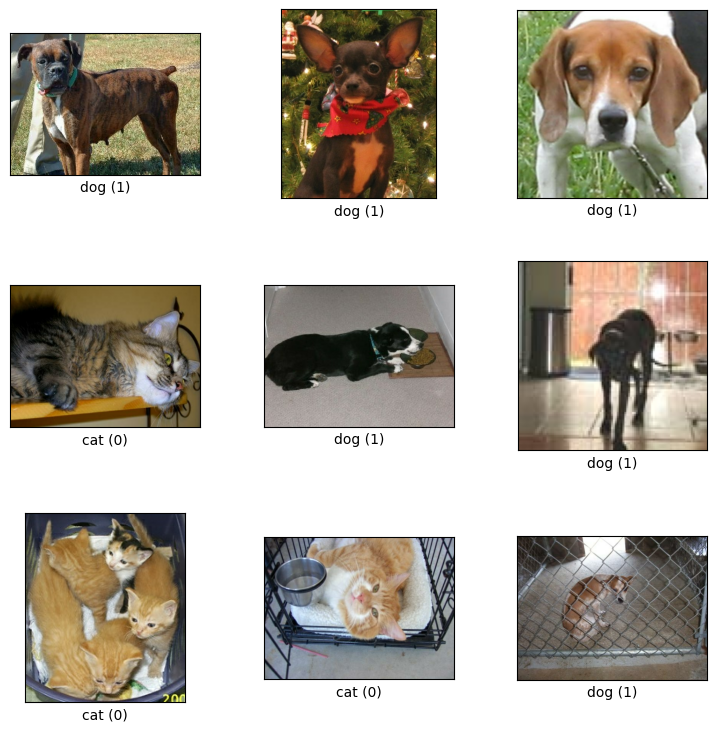

In [8]:
#Ejemplos del set original (color y tamano variable)
try:
    fig = tfds.show_examples(datos['train'], metadatos)
    fig.savefig(f'{DIR_FIG}/00_ejemplos_originales.png', dpi=150, bbox_inches='tight')
except Exception as e:
    print('No se pudo mostrar los ejemplos originales:', e)

## 4. Carga, preprocesamiento y división de los datos

`cargar_datos(img, color)` redimensiona las imágenes, las pasa a gris si corresponde, las normaliza a 0-1 y las divide en **70 % entrenamiento, 15 % validación y 15 % prueba**. Los datos se mezclan con `SEMILLA_DATOS`, así que **todos los experimentos usan exactamente las mismas imágenes en cada conjunto**, aunque cambie el tamaño o el color. Solo se mantiene en memoria la última combinación (tamaño, color) usada.

- **Entrenamiento:** ajusta los pesos.
- **Validación:** se mide en cada época (curvas de aprendizaje) y la usa EarlyStopping.
- **Prueba:** solo se usa al final, para la evaluación definitiva.

Cargando datos 100x100, grises (~0.9 GB en float32)...
  imagenes: 23262 (omitidas: 0) | train 16283 | val 3489 | test 3490


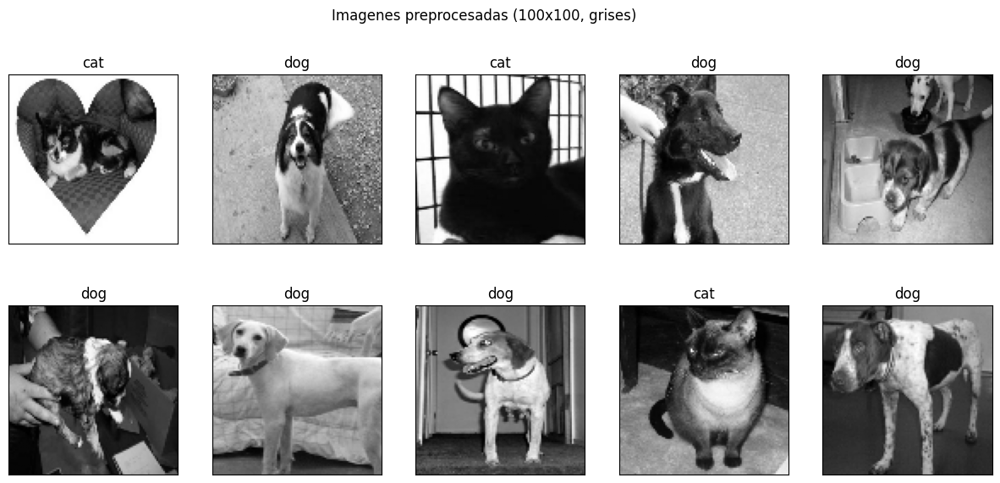

,Conjunto,Imagenes,Gatos,Perros
0,Entrenamiento,16283,8124,8159
1,Validacion,3489,1769,1720
2,Prueba,3490,1765,1725


In [9]:
_CACHE = {'clave': None, 'datos': None}
Y_TEST_REF = None   # etiquetas de prueba de referencia (deben ser iguales en todas las configuraciones)

def cargar_datos(img, color):
    global Y_TEST_REF
    clave = (img, bool(color))
    if _CACHE['clave'] == clave:
        return _CACHE['datos']
    _CACHE['clave'], _CACHE['datos'] = None, None
    gc.collect()

    canales = 3 if color else 1
    total = metadatos.splits['train'].num_examples
    print(f'Cargando datos {img}x{img}, {"color" if color else "grises"} (~{total * img * img * canales * 4 / 1e9:.1f} GB en float32)...')

    X, y, omitidas = [], [], 0
    for imagen, etiqueta in datos['train']:
        if MODO_PRUEBA and len(X) >= MAX_IMG_PRUEBA:
            break
        try:
            im = cv2.resize(imagen.numpy(), (img, img))
            if not color:
                im = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY).reshape(img, img, 1)
            X.append(im.astype(np.uint8))
            y.append(int(etiqueta.numpy()))
        except Exception:
            omitidas += 1
    X = np.array(X, dtype=np.uint8)
    y = np.array(y, dtype=np.int32)

    idx = np.random.RandomState(SEMILLA_DATOS).permutation(len(X))
    n_tr, n_va = int(len(X) * 0.70), int(len(X) * 0.15)
    partes = {'train': idx[:n_tr], 'val': idx[n_tr:n_tr + n_va], 'test': idx[n_tr + n_va:]}
    d = {}
    for k, ii in partes.items():
        d[f'X_{k}'] = np.divide(X[ii], 255, dtype=np.float32)   # normalizar a 0-1
        d[f'y_{k}'] = y[ii]
    del X; gc.collect()

    if Y_TEST_REF is None:
        Y_TEST_REF = d['y_test']
    else:
        assert np.array_equal(Y_TEST_REF, d['y_test']), 'La division de prueba cambio entre configuraciones'
    print(f'  imagenes: {len(y)} (omitidas: {omitidas}) | train {len(d["y_train"])} | val {len(d["y_val"])} | test {len(d["y_test"])}')
    _CACHE['clave'], _CACHE['datos'] = clave, d
    return d

def mostrar_img(ax, arr):
    if arr.shape[-1] == 1:
        ax.imshow(arr.reshape(arr.shape[0], arr.shape[1]), cmap='gray')
    else:
        ax.imshow(np.clip(arr, 0, 1))
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

#Primera configuracion: sirve para mostrar ejemplos y la division
cfg0 = next(iter(CONFIG.values()))
d0 = cargar_datos(cfg0['img'], cfg0['color'])

fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for i, ax in enumerate(axes.flatten()):
    mostrar_img(ax, d0['X_train'][i]); ax.set_title(NOMBRES_CLASES[d0['y_train'][i]])
fig.suptitle(f'Imagenes preprocesadas ({cfg0["img"]}x{cfg0["img"]}, {"color" if cfg0["color"] else "grises"})')
guardar_fig('01_ejemplos_preprocesados.png'); plt.show()

resumen_split = pd.DataFrame({
    'Conjunto': ['Entrenamiento', 'Validacion', 'Prueba'],
    'Imagenes': [len(d0['y_train']), len(d0['y_val']), len(d0['y_test'])],
    'Gatos': [int((d0[f'y_{k}'] == 0).sum()) for k in ['train', 'val', 'test']],
    'Perros': [int((d0[f'y_{k}'] == 1).sum()) for k in ['train', 'val', 'test']],
})
resumen_split.to_csv(f'{DIR_TAB}/00_division_datos.csv', index=False)
resumen_split

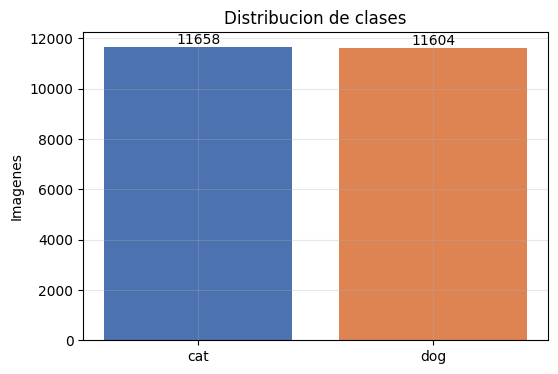

In [10]:
#Balance de clases del set completo usado
conteo = [int(sum((d0[f'y_{k}'] == c).sum() for k in ['train', 'val', 'test'])) for c in (0, 1)]
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(NOMBRES_CLASES, conteo, color=['#4c72b0', '#dd8452'])
for i, v in enumerate(conteo):
    ax.text(i, v, str(v), ha='center', va='bottom')
ax.set_title('Distribucion de clases'); ax.set_ylabel('Imagenes')
guardar_fig('02_balance_clases.png'); plt.show()

## 5. Aumento de datos

Solo se aplica a las imágenes de **entrenamiento**; validación y prueba quedan intactas. Niveles disponibles:

- `suave`: giros de 10°, desplazamientos del 10 %, zoom 0.9-1.1, volteo horizontal.
- `fuerte`: giros de 30°, desplazamientos del 20 %, cizalla, zoom 0.7-1.4, volteo horizontal.
- `original`: igual a `fuerte` más volteo vertical (como en el notebook inicial).

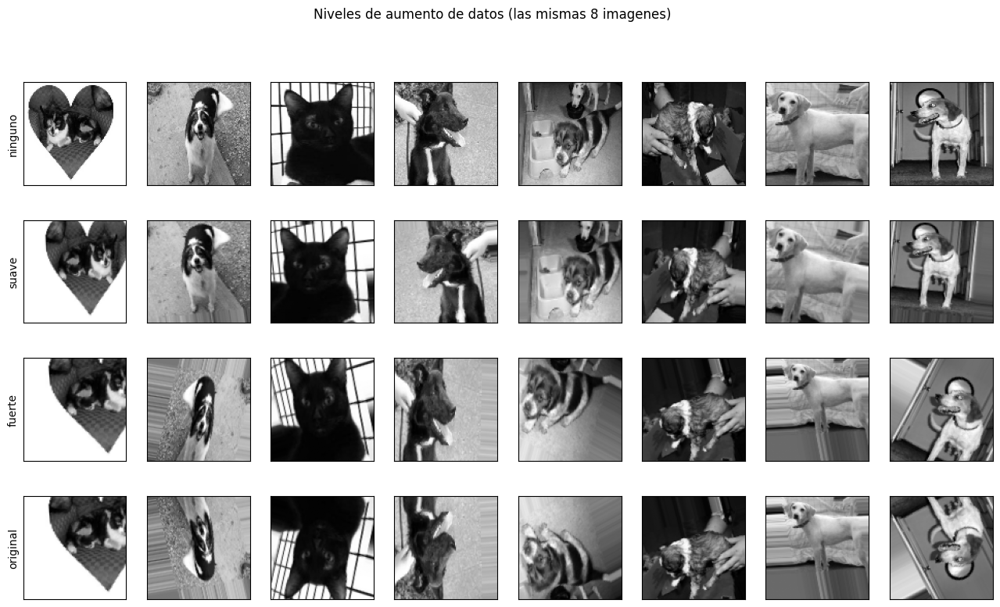

In [11]:
AUMENTOS = {
    'suave': dict(rotation_range=10, width_shift_range=0.1, height_shift_range=0.1,
                  zoom_range=[0.9, 1.1], horizontal_flip=True),
    'fuerte': dict(rotation_range=30, width_shift_range=0.2, height_shift_range=0.2,
                   shear_range=15, zoom_range=[0.7, 1.4], horizontal_flip=True),
    'original': dict(rotation_range=30, width_shift_range=0.2, height_shift_range=0.2,
                     shear_range=15, zoom_range=[0.7, 1.4], horizontal_flip=True, vertical_flip=True),
}

niveles = ['ninguno'] + list(AUMENTOS)
fig, axes = plt.subplots(len(niveles), 8, figsize=(16, 2.2 * len(niveles)))
for f, nivel in enumerate(niveles):
    if nivel == 'ninguno':
        lote = d0['X_train'][:8]
    else:
        gen = ImageDataGenerator(**AUMENTOS[nivel]).flow(d0['X_train'][:8], d0['y_train'][:8],
                                                       batch_size=8, shuffle=False, seed=SEMILLA_DATOS)
        lote = next(iter(gen))[0]
    for c in range(8):
        mostrar_img(axes[f, c], lote[c])
    axes[f, 0].set_ylabel(nivel)
fig.suptitle('Niveles de aumento de datos (las mismas 8 imagenes)')
guardar_fig('03_aumento_de_datos.png'); plt.show()

## 6. Construcción de los modelos

`construir_modelo(cfg)` arma la red según la configuración. La salida usa `sigmoid`: cerca de 0 es gato, cerca de 1 es perro. Al final se muestra una tabla con el número de parámetros de cada experimento.

In [12]:
def construir_modelo(cfg):
    L = tf.keras.layers
    canales = 3 if cfg['color'] else 1
    forma = (cfg['img'], cfg['img'], canales)
    capas = [L.Input(shape=forma)]

    if cfg['tipo'] == 'denso':
        capas.append(L.Flatten())
        for u in cfg['neuronas']:
            capas.append(L.Dense(u, activation='relu'))
            if cfg['dropout'] > 0:
                capas.append(L.Dropout(cfg['dropout']))

    elif cfg['tipo'] == 'cnn':
        for f in cfg['filtros']:
            capas.append(L.Conv2D(f, (3, 3), activation='relu'))
            if cfg['batchnorm']:
                capas.append(L.BatchNormalization())
            capas.append(L.MaxPooling2D(2, 2))
        if cfg['dropout'] > 0:
            capas.append(L.Dropout(cfg['dropout']))
        capas.append(L.Flatten())
        for u in cfg['neuronas']:
            capas.append(L.Dense(u, activation='relu'))

    elif cfg['tipo'] == 'mobilenet':
        base = tf.keras.applications.MobileNetV2(input_shape=forma, include_top=False, weights='imagenet')
        base.trainable = False                       # base congelada: solo se entrena la cabeza
        capas.append(L.Rescaling(2.0, offset=-1.0))  # MobileNetV2 espera entradas en [-1, 1]; nuestras imagenes van en [0, 1]
        capas.append(base)
        capas.append(L.GlobalAveragePooling2D())
        if cfg['dropout'] > 0:
            capas.append(L.Dropout(cfg['dropout']))

    capas.append(L.Dense(1, activation='sigmoid'))
    return tf.keras.models.Sequential(capas)

def crear_optimizador(cfg):
    o, lr = cfg['optimizador'].lower(), cfg['lr']
    if o == 'adam':
        return tf.keras.optimizers.Adam(learning_rate=lr)
    if o == 'rmsprop':
        return tf.keras.optimizers.RMSprop(learning_rate=lr)
    if o == 'sgd':
        return tf.keras.optimizers.SGD(learning_rate=lr, momentum=0.9)
    raise ValueError(f'Optimizador desconocido: {o}')

def contar_entrenables(m):
    return int(sum(np.prod(w.shape) for w in m.trainable_weights))

filas = []
for nombre, cfg in CONFIG.items():
    m = construir_modelo(cfg)
    filas.append({'Modelo': nombre, 'Grupo': cfg['grupo'], 'Tipo': cfg['tipo'],
                  'Parametros totales': m.count_params(), 'Parametros entrenables': contar_entrenables(m)})
    tf.keras.backend.clear_session()
tabla_arq = pd.DataFrame(filas).set_index('Modelo')
tabla_arq.to_csv(f'{DIR_TAB}/01_arquitecturas.csv')
tabla_arq

,Grupo,Tipo,Parametros totales,Parametros entrenables
Modelo,,,,
Denso,Sin aumento de datos,denso,1522951,1522951
CNN,Sin aumento de datos,cnn,1372873,1372873
CNN2 (Dropout 0.5),Sin aumento de datos,cnn,3293173,3293173
Denso + AD,Con aumento de datos,denso,1522951,1522951
CNN + AD,Con aumento de datos,cnn,1372873,1372873
CNN2 (Dropout 0.5) + AD,Con aumento de datos,cnn,3293173,3293173


In [13]:
#Detalle de capas de un modelo (cambiar el nombre por el que quieras revisar)
m = construir_modelo(CONFIG[next(iter(CONFIG))])
m.summary()
tf.keras.backend.clear_session()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 10000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 150)            │     1,500,150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 150)            │        22,650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           151 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,522,951 (5.81 MB)

 Trainable params: 1,522,951 (5.81 MB)

 Non-trainable params: 0 (0.00 B)

## 7. Entrenamiento

Para cada experimento y cada semilla se entrena el modelo y se guarda en `informe/resultados/` el **historial** (accuracy y loss por época), el **tiempo**, el número de parámetros y las **probabilidades sobre el conjunto de prueba**. Si ya existe, se carga en vez de reentrenar.

El progreso se imprime cada 10 épocas. Los logs de TensorBoard se guardan en `logs/`.

In [14]:
def slug(s):
    return re.sub(r'[^A-Za-z0-9]+', '_', s).strip('_')

def id_corrida(nombre, cfg, semilla):
    clave = {k: v for k, v in cfg.items() if k != 'grupo'}
    clave.update(semilla=semilla, semilla_datos=SEMILLA_DATOS, prueba=MODO_PRUEBA)
    h = hashlib.md5(json.dumps(clave, sort_keys=True, default=str).encode()).hexdigest()[:8]
    return f'{slug(nombre)}_s{semilla}_{h}'

class Progreso(tf.keras.callbacks.Callback):
    def __init__(self, nombre, cada=10):
        super().__init__(); self.nombre, self.cada = nombre, cada
    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0 or (epoch + 1) % self.cada == 0:
            print(f'  [{self.nombre}] epoca {epoch + 1}: acc={logs["accuracy"]:.3f} val_acc={logs["val_accuracy"]:.3f} '
                  f'loss={logs["loss"]:.3f} val_loss={logs["val_loss"]:.3f}')

def ejecutar(nombre, cfg, semilla):
    cid = id_corrida(nombre, cfg, semilla)
    ruta = f'{DIR_RES}/{cid}.pkl'
    if os.path.exists(ruta):
        print(f'[{nombre} | semilla {semilla}] ya entrenado: se carga de disco.')
        with open(ruta, 'rb') as f:
            return pickle.load(f)

    d = cargar_datos(cfg['img'], cfg['color'])
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(semilla)
    modelo = construir_modelo(cfg)
    modelo.compile(optimizer=crear_optimizador(cfg), loss='binary_crossentropy', metrics=['accuracy'])

    callbacks = [TensorBoard(log_dir=f'logs/{cid}'), Progreso(nombre)]
    if cfg['early_stopping']:
        callbacks.append(EarlyStopping(monitor='val_loss', patience=cfg['paciencia'], restore_best_weights=True))

    print(f'\n[{nombre} | semilla {semilla}] entrenando hasta {cfg["epochs"]} epocas...')
    t0 = time.time()
    if cfg['aumento'] == 'ninguno':
        h = modelo.fit(d['X_train'], d['y_train'], batch_size=cfg['batch'], epochs=cfg['epochs'],
                       validation_data=(d['X_val'], d['y_val']), callbacks=callbacks, verbose=0)
    else:
        gen = ImageDataGenerator(**AUMENTOS[cfg['aumento']]).flow(
            d['X_train'], d['y_train'], batch_size=cfg['batch'], seed=semilla)
        h = modelo.fit(gen, epochs=cfg['epochs'],
                       steps_per_epoch=int(np.ceil(len(d['X_train']) / cfg['batch'])),
                       validation_data=(d['X_val'], d['y_val']), callbacks=callbacks, verbose=0)
    tiempo = time.time() - t0

    probs = modelo.predict(d['X_test'], batch_size=cfg['batch'], verbose=0).ravel()
    ruta_modelo = None
    if GUARDAR_MODELOS:
        ruta_modelo = f'{DIR_MODELOS}/{cid}.h5'
        modelo.save(ruta_modelo)

    r = {'nombre': nombre, 'semilla': semilla, 'cfg': cfg, 'history': h.history, 'tiempo_s': tiempo,
         'params': modelo.count_params(), 'params_entrenables': contar_entrenables(modelo),
         'probs_test': probs, 'ruta_modelo': ruta_modelo}
    with open(ruta, 'wb') as f:
        pickle.dump(r, f)
    print(f'[{nombre} | semilla {semilla}] listo en {tiempo / 60:.1f} min ({len(h.history["loss"])} epocas)')
    tf.keras.backend.clear_session()
    return r

In [15]:
#Ejecuta todos los experimentos. Si se corta, volver a ejecutar esta celda: continua donde quedo.
RES = {}
for nombre, cfg in CONFIG.items():
    for semilla in SEMILLAS:
        RES[(nombre, semilla)] = ejecutar(nombre, cfg, semilla)
print('\nCorridas disponibles:', len(RES))


[Denso | semilla 42] entrenando hasta 100 epocas...
  [Denso] epoca 1: acc=0.536 val_acc=0.538 loss=0.722 val_loss=0.683
  [Denso] epoca 10: acc=0.609 val_acc=0.579 loss=0.658 val_loss=0.671
  [Denso] epoca 20: acc=0.625 val_acc=0.579 loss=0.645 val_loss=0.673
  [Denso] epoca 30: acc=0.642 val_acc=0.589 loss=0.634 val_loss=0.674
  [Denso] epoca 40: acc=0.667 val_acc=0.590 loss=0.615 val_loss=0.683
  [Denso] epoca 50: acc=0.682 val_acc=0.575 loss=0.601 val_loss=0.721
  [Denso] epoca 60: acc=0.642 val_acc=0.522 loss=0.619 val_loss=0.712
  [Denso] epoca 70: acc=0.675 val_acc=0.582 loss=0.600 val_loss=0.721
  [Denso] epoca 80: acc=0.710 val_acc=0.580 loss=0.567 val_loss=0.772
  [Denso] epoca 90: acc=0.560 val_acc=0.496 loss=0.658 val_loss=0.693
  [Denso] epoca 100: acc=0.549 val_acc=0.498 loss=0.663 val_loss=0.691


[Denso | semilla 42] listo en 4.2 min (100 epocas)

[CNN | semilla 42] entrenando hasta 100 epocas...
  [CNN] epoca 1: acc=0.590 val_acc=0.686 loss=0.660 val_loss=0.597
  [CNN] epoca 10: acc=0.923 val_acc=0.794 loss=0.189 val_loss=0.562
  [CNN] epoca 20: acc=0.992 val_acc=0.790 loss=0.027 val_loss=1.313
  [CNN] epoca 30: acc=0.992 val_acc=0.800 loss=0.023 val_loss=1.413
  [CNN] epoca 40: acc=0.998 val_acc=0.790 loss=0.008 val_loss=1.681
  [CNN] epoca 50: acc=0.997 val_acc=0.797 loss=0.007 val_loss=1.709
  [CNN] epoca 60: acc=1.000 val_acc=0.801 loss=0.000 val_loss=2.058
  [CNN] epoca 70: acc=0.983 val_acc=0.790 loss=0.068 val_loss=1.516
  [CNN] epoca 80: acc=0.999 val_acc=0.798 loss=0.003 val_loss=1.895
  [CNN] epoca 90: acc=0.995 val_acc=0.798 loss=0.018 val_loss=1.862
  [CNN] epoca 100: acc=0.996 val_acc=0.787 loss=0.013 val_loss=2.177


[CNN | semilla 42] listo en 11.5 min (100 epocas)

[CNN2 (Dropout 0.5) | semilla 42] entrenando hasta 100 epocas...
  [CNN2 (Dropout 0.5)] epoca 1: acc=0.583 val_acc=0.681 loss=0.668 val_loss=0.624
  [CNN2 (Dropout 0.5)] epoca 10: acc=0.910 val_acc=0.839 loss=0.212 val_loss=0.407
  [CNN2 (Dropout 0.5)] epoca 20: acc=0.976 val_acc=0.832 loss=0.069 val_loss=0.601
  [CNN2 (Dropout 0.5)] epoca 30: acc=0.988 val_acc=0.838 loss=0.039 val_loss=0.711
  [CNN2 (Dropout 0.5)] epoca 40: acc=0.988 val_acc=0.830 loss=0.035 val_loss=0.824
  [CNN2 (Dropout 0.5)] epoca 50: acc=0.993 val_acc=0.846 loss=0.024 val_loss=0.768
  [CNN2 (Dropout 0.5)] epoca 60: acc=0.994 val_acc=0.842 loss=0.020 val_loss=0.834
  [CNN2 (Dropout 0.5)] epoca 70: acc=0.994 val_acc=0.842 loss=0.018 val_loss=0.941
  [CNN2 (Dropout 0.5)] epoca 80: acc=0.993 val_acc=0.830 loss=0.021 val_loss=0.862
  [CNN2 (Dropout 0.5)] epoca 90: acc=0.995 val_acc=0.839 loss=0.016 val_loss=0.966
  [CNN2 (Dropout 0.5)] epoca 100: acc=0.995 val_acc=0.8

[CNN2 (Dropout 0.5) | semilla 42] listo en 12.1 min (100 epocas)

[Denso + AD | semilla 42] entrenando hasta 100 epocas...
  [Denso + AD] epoca 1: acc=0.511 val_acc=0.517 loss=0.725 val_loss=0.695
  [Denso + AD] epoca 10: acc=0.518 val_acc=0.501 loss=0.691 val_loss=0.692
  [Denso + AD] epoca 20: acc=0.527 val_acc=0.511 loss=0.690 val_loss=0.690
  [Denso + AD] epoca 30: acc=0.531 val_acc=0.509 loss=0.689 val_loss=0.691
  [Denso + AD] epoca 40: acc=0.545 val_acc=0.519 loss=0.686 val_loss=0.692
  [Denso + AD] epoca 50: acc=0.538 val_acc=0.516 loss=0.687 val_loss=0.691
  [Denso + AD] epoca 60: acc=0.552 val_acc=0.527 loss=0.684 val_loss=0.691
  [Denso + AD] epoca 70: acc=0.549 val_acc=0.530 loss=0.684 val_loss=0.689
  [Denso + AD] epoca 80: acc=0.549 val_acc=0.538 loss=0.686 val_loss=0.687
  [Denso + AD] epoca 90: acc=0.550 val_acc=0.540 loss=0.684 val_loss=0.686
  [Denso + AD] epoca 100: acc=0.556 val_acc=0.545 loss=0.684 val_loss=0.686


[Denso + AD | semilla 42] listo en 29.2 min (100 epocas)

[CNN + AD | semilla 42] entrenando hasta 100 epocas...
  [CNN + AD] epoca 1: acc=0.543 val_acc=0.548 loss=0.687 val_loss=0.685
  [CNN + AD] epoca 10: acc=0.691 val_acc=0.730 loss=0.582 val_loss=0.529
  [CNN + AD] epoca 20: acc=0.749 val_acc=0.777 loss=0.509 val_loss=0.467
  [CNN + AD] epoca 30: acc=0.775 val_acc=0.815 loss=0.468 val_loss=0.410
  [CNN + AD] epoca 40: acc=0.794 val_acc=0.826 loss=0.437 val_loss=0.385
  [CNN + AD] epoca 50: acc=0.809 val_acc=0.834 loss=0.415 val_loss=0.366
  [CNN + AD] epoca 60: acc=0.815 val_acc=0.860 loss=0.402 val_loss=0.328
  [CNN + AD] epoca 70: acc=0.823 val_acc=0.847 loss=0.389 val_loss=0.355
  [CNN + AD] epoca 80: acc=0.827 val_acc=0.861 loss=0.377 val_loss=0.336
  [CNN + AD] epoca 90: acc=0.837 val_acc=0.866 loss=0.360 val_loss=0.317
  [CNN + AD] epoca 100: acc=0.840 val_acc=0.881 loss=0.356 val_loss=0.278


[CNN + AD | semilla 42] listo en 33.5 min (100 epocas)

[CNN2 (Dropout 0.5) + AD | semilla 42] entrenando hasta 100 epocas...
  [CNN2 (Dropout 0.5) + AD] epoca 1: acc=0.542 val_acc=0.551 loss=0.688 val_loss=0.681
  [CNN2 (Dropout 0.5) + AD] epoca 10: acc=0.690 val_acc=0.735 loss=0.581 val_loss=0.536
  [CNN2 (Dropout 0.5) + AD] epoca 20: acc=0.732 val_acc=0.763 loss=0.534 val_loss=0.499
  [CNN2 (Dropout 0.5) + AD] epoca 30: acc=0.752 val_acc=0.806 loss=0.504 val_loss=0.424
  [CNN2 (Dropout 0.5) + AD] epoca 40: acc=0.773 val_acc=0.817 loss=0.476 val_loss=0.398
  [CNN2 (Dropout 0.5) + AD] epoca 50: acc=0.786 val_acc=0.801 loss=0.459 val_loss=0.433
  [CNN2 (Dropout 0.5) + AD] epoca 60: acc=0.793 val_acc=0.825 loss=0.442 val_loss=0.379
  [CNN2 (Dropout 0.5) + AD] epoca 70: acc=0.795 val_acc=0.844 loss=0.437 val_loss=0.355
  [CNN2 (Dropout 0.5) + AD] epoca 80: acc=0.802 val_acc=0.825 loss=0.422 val_loss=0.383
  [CNN2 (Dropout 0.5) + AD] epoca 90: acc=0.814 val_acc=0.850 loss=0.406 val_loss=0

[CNN2 (Dropout 0.5) + AD | semilla 42] listo en 33.8 min (100 epocas)

Corridas disponibles: 6


## 8. Curvas de aprendizaje

Con una sola semilla se grafica esa corrida; con varias, la **media** con una banda de ±1 desviación estándar.

### 8.1 Una figura por experimento (entrenamiento vs. validación)

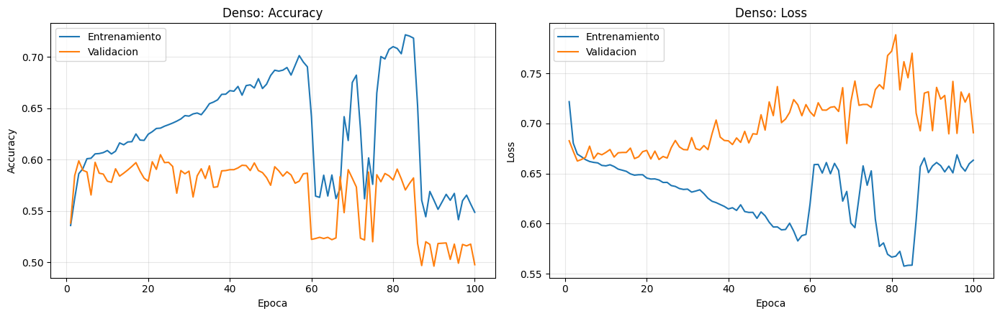

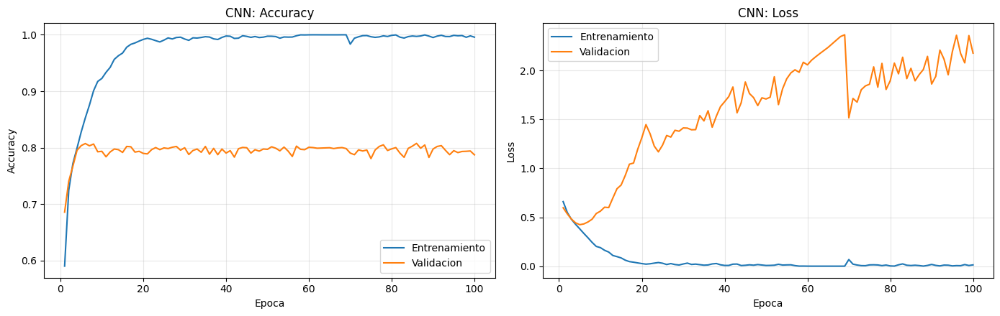

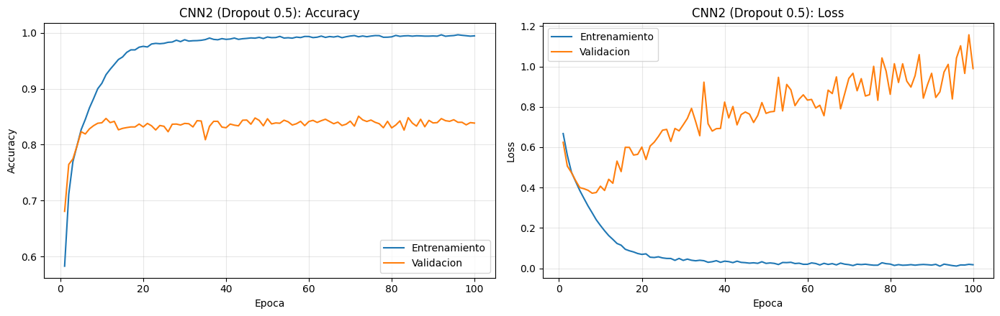

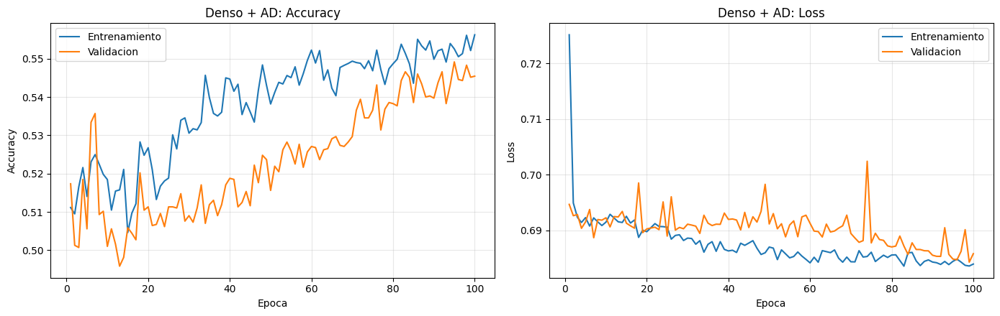

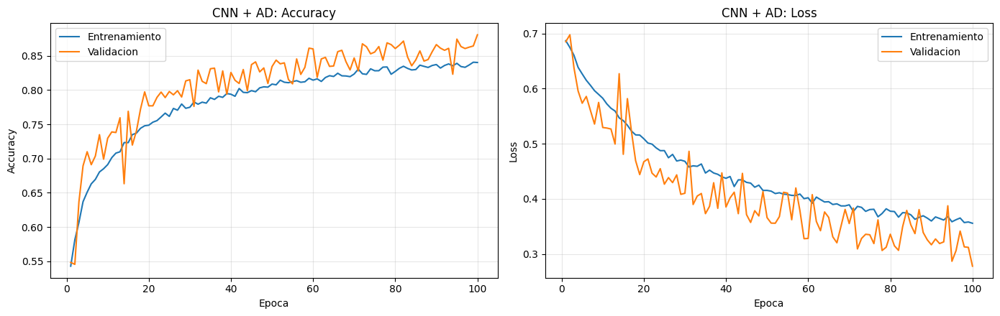

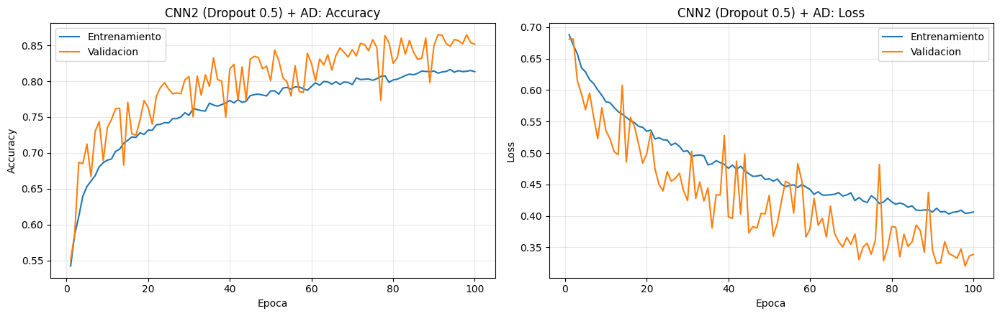

In [16]:
def curva(nombre, clave):
    series = [RES[(nombre, s)]['history'][clave] for s in SEMILLAS]
    n = max(len(s) for s in series)
    M = np.full((len(series), n), np.nan)
    for i, s in enumerate(series):
        M[i, :len(s)] = s
    media = np.nanmean(M, axis=0)
    desv = np.nanstd(M, axis=0) if len(series) > 1 else None
    return media, desv

def trazar(ax, nombre, clave, etiqueta, **kw):
    m, s = curva(nombre, clave)
    x = np.arange(1, len(m) + 1)
    linea, = ax.plot(x, m, label=etiqueta, **kw)
    if s is not None:
        ax.fill_between(x, m - s, m + s, alpha=0.2, color=linea.get_color())

def graficar_corrida(nombre):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    for a, (k_tr, k_va, tit) in zip(ax, [('accuracy', 'val_accuracy', 'Accuracy'), ('loss', 'val_loss', 'Loss')]):
        trazar(a, nombre, k_tr, 'Entrenamiento')
        trazar(a, nombre, k_va, 'Validacion')
        a.set_title(f'{nombre}: {tit}'); a.set_xlabel('Epoca'); a.set_ylabel(tit); a.legend()
    plt.tight_layout()
    guardar_fig(f'04_curvas_{slug(nombre)}.png'); plt.show()

if GRAFICAS_INDIVIDUALES:
    for nombre in CONFIG:
        graficar_corrida(nombre)

### 8.2 Comparación dentro de cada grupo

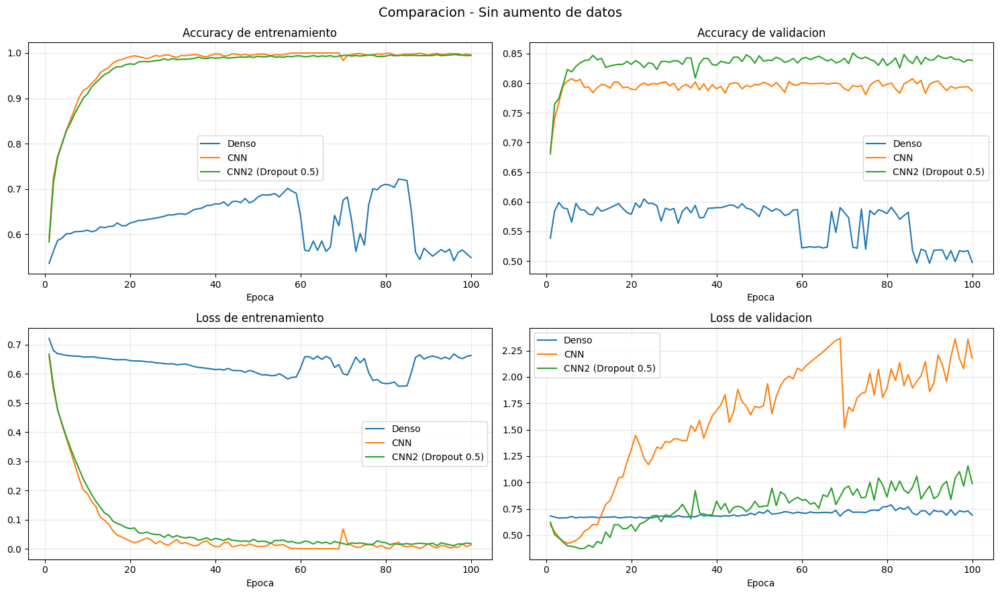

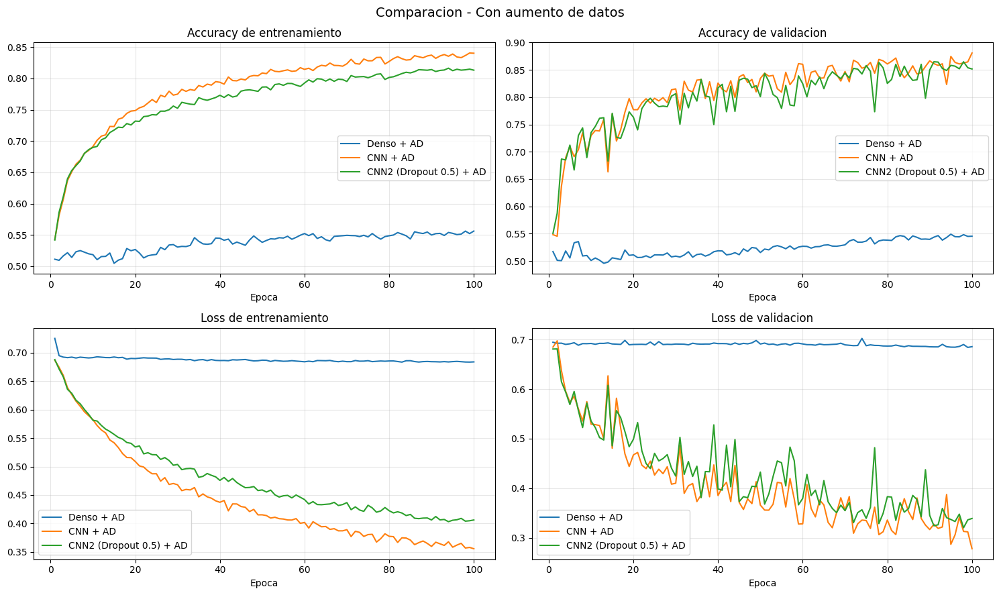

In [17]:
def comparar(nombres, titulo, archivo):
    fig, ax = plt.subplots(2, 2, figsize=(15, 9))
    for nombre in nombres:
        trazar(ax[0, 0], nombre, 'accuracy', nombre)
        trazar(ax[0, 1], nombre, 'val_accuracy', nombre)
        trazar(ax[1, 0], nombre, 'loss', nombre)
        trazar(ax[1, 1], nombre, 'val_loss', nombre)
    for a, t in zip(ax.flatten(), ['Accuracy de entrenamiento', 'Accuracy de validacion',
                                   'Loss de entrenamiento', 'Loss de validacion']):
        a.set_title(t); a.set_xlabel('Epoca'); a.legend()
    fig.suptitle(titulo, fontsize=14)
    plt.tight_layout()
    guardar_fig(archivo); plt.show()

for i, (grupo, nombres) in enumerate(GRUPOS.items()):
    if len(nombres) >= 2:
        comparar(nombres, f'Comparacion - {grupo}', f'05_comparacion_{i + 1}_{slug(grupo)}.png')

## 9. Tabla resumen de entrenamiento

- **Acc. final train / val:** accuracy en la última época entrenada.
- **Mejor acc. val y época:** el mejor valor de validación y cuándo ocurrió.
- **Menor loss val y época:** a partir de ahí, si la loss de validación sube, el modelo empieza a memorizar.
- **Gap acc. final:** accuracy de entrenamiento menos validación en la última época. Un gap grande indica **sobreajuste**.
- **Gap en época de menor loss val:** el mismo gap, pero en el mejor momento del modelo (útil con EarlyStopping).

In [18]:
filas = []
for (nombre, semilla), r in RES.items():
    h = r['history']
    va, vl = np.array(h['val_accuracy']), np.array(h['val_loss'])
    i = int(vl.argmin())
    filas.append({
        'Modelo': nombre, 'Grupo': r['cfg']['grupo'], 'Semilla': semilla,
        'Parametros': r['params'], 'Param. entrenables': r['params_entrenables'],
        'Epocas ejecutadas': len(va),
        'Acc. final train': h['accuracy'][-1], 'Acc. final val': va[-1],
        'Mejor acc. val': va.max(), 'Epoca mejor acc. val': int(va.argmax()) + 1,
        'Loss final train': h['loss'][-1], 'Loss final val': vl[-1],
        'Menor loss val': vl.min(), 'Epoca menor loss val': i + 1,
        'Gap acc. final (train-val)': h['accuracy'][-1] - va[-1],
        'Gap en epoca menor loss val': h['accuracy'][i] - va[i],
        'Tiempo (min)': r['tiempo_s'] / 60,
    })
tabla_runs = pd.DataFrame(filas)
tabla_runs.to_csv(f'{DIR_TAB}/02_resumen_entrenamiento_por_corrida.csv', index=False)

def agregar(df, columnas):
    g = df.groupby('Modelo', sort=False)[columnas]
    m = g.mean()
    if len(SEMILLAS) > 1:
        m = m.join(g.std().add_suffix(' (std)'))
    return m

cols_train = ['Parametros', 'Param. entrenables', 'Epocas ejecutadas', 'Acc. final train', 'Acc. final val',
              'Mejor acc. val', 'Epoca mejor acc. val', 'Loss final train', 'Loss final val', 'Menor loss val',
              'Epoca menor loss val', 'Gap acc. final (train-val)', 'Gap en epoca menor loss val', 'Tiempo (min)']
tabla_train = agregar(tabla_runs, cols_train)
tabla_train.insert(0, 'Grupo', [CONFIG[n]['grupo'] for n in tabla_train.index])
tabla_train.to_csv(f'{DIR_TAB}/02_resumen_entrenamiento.csv')
tabla_train.round(4)

,Grupo,Parametros,Param. entrenables,Epocas ejecutadas,Acc. final train,Acc. final val,Mejor acc. val,Epoca mejor acc. val,Loss final train,Loss final val,Menor loss val,Epoca menor loss val,Gap acc. final (train-val),Gap en epoca menor loss val,Tiempo (min)
Modelo,,,,,,,,,,,,,,,
Denso,Sin aumento de datos,1522951.0,1522951.0,100.0,0.5486,0.4976,0.6048,23.0,0.6633,0.6908,0.6625,3.0,0.0510,-0.0125,4.1971
CNN,Sin aumento de datos,1372873.0,1372873.0,100.0,0.9957,0.7873,0.8077,86.0,0.0132,2.1774,0.4241,5.0,0.2084,0.0240,11.4956
CNN2 (Dropout 0.5),Sin aumento de datos,3293173.0,3293173.0,100.0,0.9947,0.8386,0.8510,72.0,0.0176,0.9899,0.3721,8.0,0.1561,0.0484,12.0905
Denso + AD,Con aumento de datos,1522951.0,1522951.0,100.0,0.5562,0.5454,0.5492,95.0,0.6839,0.6858,0.6843,99.0,0.0108,0.0070,29.1896
CNN + AD,Con aumento de datos,1372873.0,1372873.0,100.0,0.8403,0.8808,0.8808,100.0,0.3556,0.2777,0.2777,100.0,-0.0404,-0.0404,33.5302
CNN2 (Dropout 0.5) + AD,Con aumento de datos,3293173.0,3293173.0,100.0,0.8132,0.8515,0.8647,91.0,0.4061,0.3389,0.3201,98.0,-0.0383,-0.0509,33.8188


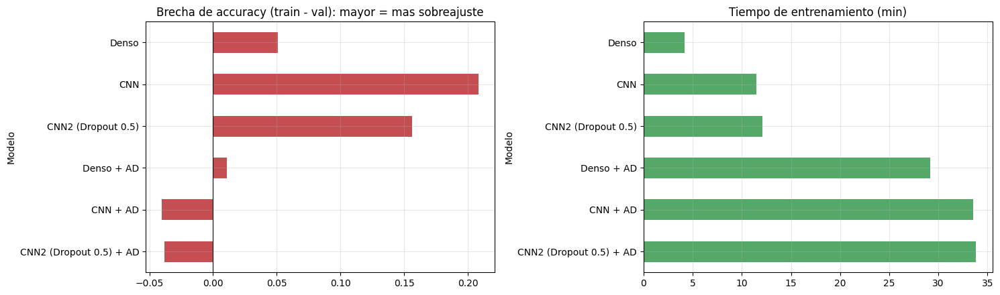

In [19]:
#Brecha train-val (sobreajuste) y tiempo de entrenamiento
fig, ax = plt.subplots(1, 2, figsize=(15, max(4, 0.5 * len(tabla_train) + 1.5)))
tabla_train['Gap acc. final (train-val)'].iloc[::-1].plot(kind='barh', ax=ax[0], color='#c44e52')
ax[0].set_title('Brecha de accuracy (train - val): mayor = mas sobreajuste'); ax[0].axvline(0, color='black', linewidth=0.8)
tabla_train['Tiempo (min)'].iloc[::-1].plot(kind='barh', ax=ax[1], color='#55a868')
ax[1].set_title('Tiempo de entrenamiento (min)')
plt.tight_layout(); guardar_fig('06_sobreajuste_y_tiempo.png'); plt.show()

## 10. Evaluación final en el conjunto de prueba (test)

Es la medida **más honesta** del rendimiento: los modelos nunca vieron estas imágenes ni las usaron para decidir nada (ni siquiera EarlyStopping, que usa validación). Se calculan accuracy, loss, precisión, recall, F1, AUC, matriz de confusión y curva ROC.

In [20]:
y_test = Y_TEST_REF

def metricas_test(probs, y):
    pred = (probs > 0.5).astype(int)
    p = np.clip(probs, 1e-7, 1 - 1e-7)
    loss = float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))
    pr, rc, f1, _ = precision_recall_fscore_support(y, pred, average='macro', zero_division=0)
    fpr, tpr, _ = roc_curve(y, probs)
    return {'pred': pred, 'fpr': fpr, 'tpr': tpr,
            'Accuracy test': float((pred == y).mean()), 'Loss test': loss,
            'Precision (macro)': float(pr), 'Recall (macro)': float(rc), 'F1 (macro)': float(f1),
            'AUC': float(auc(fpr, tpr))}

MET = {k: metricas_test(r['probs_test'], y_test) for k, r in RES.items()}

cols_test = ['Accuracy test', 'Loss test', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)', 'AUC']
tabla_test_runs = pd.DataFrame([{'Modelo': n, 'Semilla': s, **{c: MET[(n, s)][c] for c in cols_test}} for (n, s) in RES])
tabla_test_runs.to_csv(f'{DIR_TAB}/03_resultados_test_por_corrida.csv', index=False)
tabla_test = agregar(tabla_test_runs, cols_test)
tabla_test.to_csv(f'{DIR_TAB}/03_resultados_test.csv')
tabla_test.round(4)

,Accuracy test,Loss test,Precision (macro),Recall (macro),F1 (macro),AUC
Modelo,,,,,,
Denso,0.4977,0.6917,0.7480,0.5034,0.3383,0.5031
CNN,0.8020,1.6046,0.8042,0.8015,0.8014,0.8854
CNN2 (Dropout 0.5),0.8470,0.8431,0.8470,0.8471,0.8470,0.9226
Denso + AD,0.5622,0.6834,0.5623,0.5623,0.5622,0.5774
CNN + AD,0.8768,0.2874,0.8787,0.8772,0.8767,0.9535
CNN2 (Dropout 0.5) + AD,0.8576,0.3336,0.8582,0.8578,0.8576,0.9349


In [21]:
#Reporte de clasificacion por clase (primera semilla)
REPORTES = {}
for nombre in CONFIG:
    pred = MET[(nombre, SEMILLAS[0])]['pred']
    REPORTES[nombre] = classification_report(y_test, pred, target_names=NOMBRES_CLASES, digits=4)
    print(f'\n===== {nombre} =====')
    print(REPORTES[nombre])


===== Denso =====
              precision    recall  f1-score   support

         cat     1.0000    0.0068    0.0135      1765
         dog     0.4960    1.0000    0.6631      1725

    accuracy                         0.4977      3490
   macro avg     0.7480    0.5034    0.3383      3490
weighted avg     0.7509    0.4977    0.3346      3490


===== CNN =====
              precision    recall  f1-score   support

         cat     0.7809    0.8459    0.8121      1765
         dog     0.8276    0.7571    0.7908      1725

    accuracy                         0.8020      3490
   macro avg     0.8042    0.8015    0.8014      3490
weighted avg     0.8040    0.8020    0.8016      3490


===== CNN2 (Dropout 0.5) =====
              precision    recall  f1-score   support

         cat     0.8548    0.8402    0.8474      1765
         dog     0.8393    0.8539    0.8466      1725

    accuracy                         0.8470      3490
   macro avg     0.8470    0.8471    0.8470      3490
weight

### 10.1 Matrices de confusión (primera semilla)

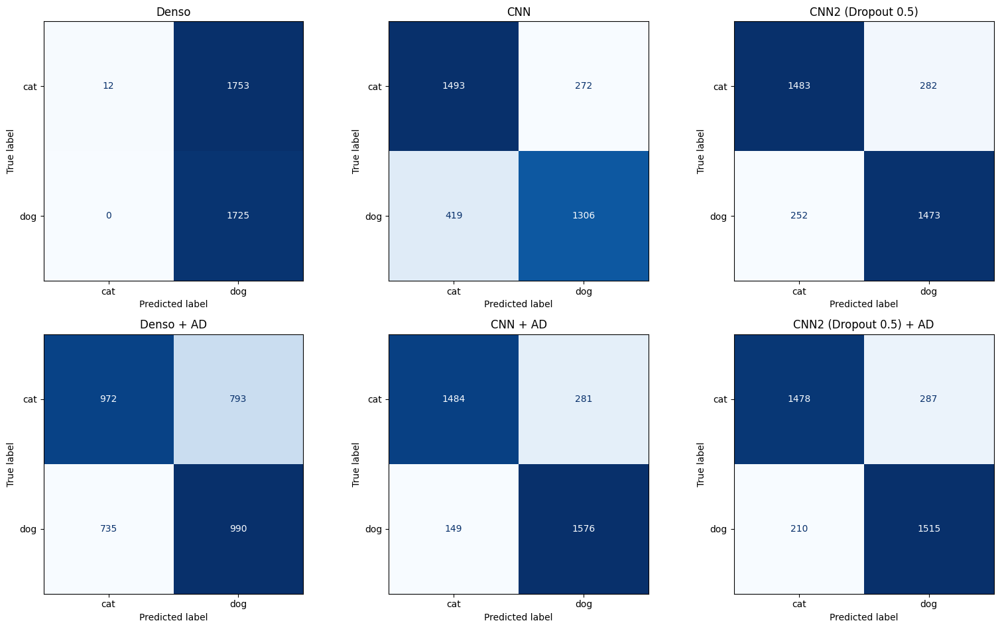

In [22]:
n_mod = len(CONFIG)
cols = min(3, n_mod)
filas_fig = int(np.ceil(n_mod / cols))
fig, axes = plt.subplots(filas_fig, cols, figsize=(5.3 * cols, 4.8 * filas_fig))
axes = np.array(axes).reshape(-1)
MATRICES = {}
for ax, nombre in zip(axes, CONFIG):
    cm = confusion_matrix(y_test, MET[(nombre, SEMILLAS[0])]['pred'])
    MATRICES[nombre] = cm
    ConfusionMatrixDisplay(cm, display_labels=NOMBRES_CLASES).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(nombre); ax.grid(False)
for ax in axes[n_mod:]:
    ax.axis('off')
plt.tight_layout(); guardar_fig('07_matrices_confusion.png'); plt.show()

### 10.2 Curvas ROC (primera semilla)

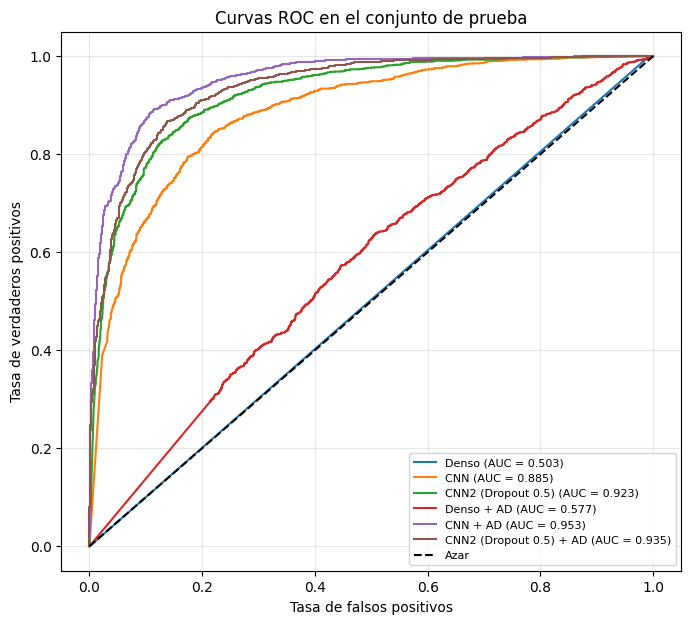

In [23]:
plt.figure(figsize=(8, 7))
for nombre in CONFIG:
    m = MET[(nombre, SEMILLAS[0])]
    plt.plot(m['fpr'], m['tpr'], label=f"{nombre} (AUC = {m['AUC']:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Azar')
plt.xlabel('Tasa de falsos positivos'); plt.ylabel('Tasa de verdaderos positivos')
plt.title('Curvas ROC en el conjunto de prueba'); plt.legend(fontsize=8)
guardar_fig('08_curvas_roc.png'); plt.show()

### 10.3 Accuracy de prueba de todos los modelos

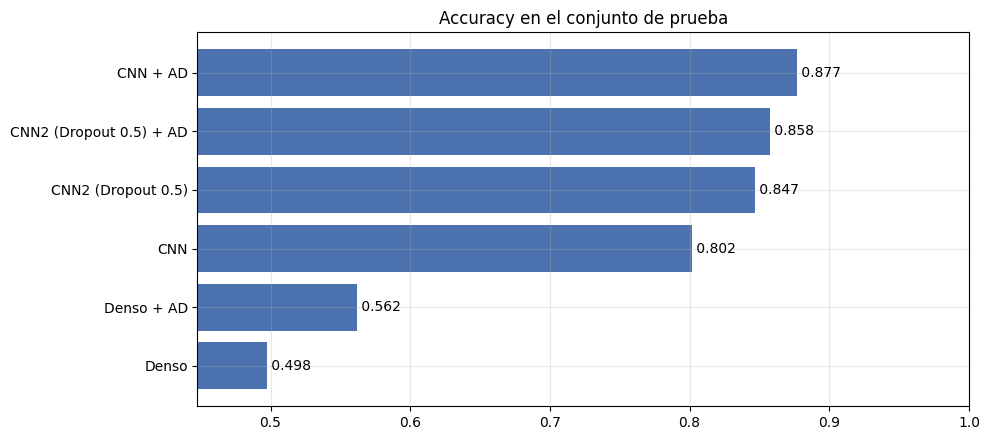

Mejor modelo en test: CNN + AD (accuracy = 0.8768)


In [24]:
orden = tabla_test['Accuracy test'].sort_values()
err = tabla_test['Accuracy test (std)'].reindex(orden.index) if 'Accuracy test (std)' in tabla_test else None
fig, ax = plt.subplots(figsize=(10, max(4, 0.5 * len(orden) + 1.5)))
barras = ax.barh(orden.index, orden.values, xerr=err, color='#4c72b0', capsize=3)
for b, v in zip(barras, orden.values):
    ax.text(v, b.get_y() + b.get_height() / 2, f' {v:.3f}', va='center')
ax.set_xlim(max(0.4, orden.min() - 0.05), 1.0)
ax.set_title('Accuracy en el conjunto de prueba' + (' (media ± std)' if err is not None else ''))
plt.tight_layout(); guardar_fig('09_accuracy_test.png'); plt.show()

MEJOR = tabla_test['Accuracy test'].idxmax()
print(f'Mejor modelo en test: {MEJOR} (accuracy = {tabla_test.loc[MEJOR, "Accuracy test"]:.4f})')

## 11. Análisis de errores del mejor modelo

Ver en qué imágenes se equivoca el modelo ayuda a explicar sus limitaciones en el informe (animales de espaldas, fondos complicados, imágenes borrosas, etc.).

CNN + AD: 430 errores de 3490 imagenes de prueba


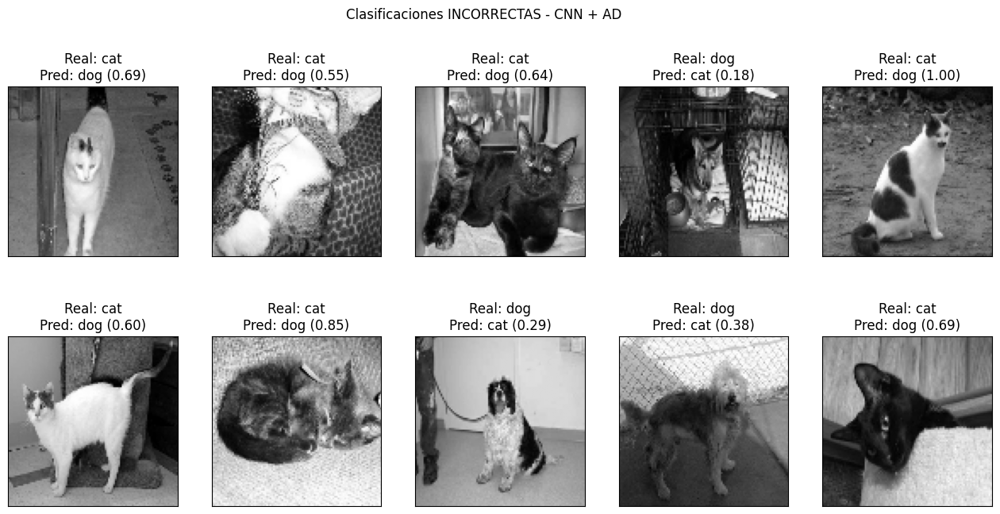

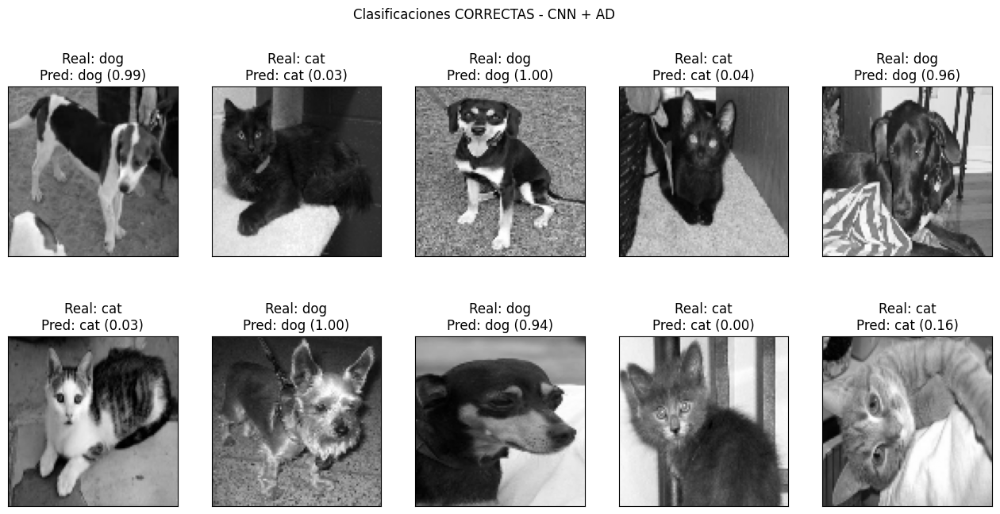

In [25]:
cfgM = CONFIG[MEJOR]
dM = cargar_datos(cfgM['img'], cfgM['color'])
mM = MET[(MEJOR, SEMILLAS[0])]
probsM = RES[(MEJOR, SEMILLAS[0])]['probs_test']
errores = np.where(mM['pred'] != y_test)[0]
aciertos = np.where(mM['pred'] == y_test)[0]
print(f'{MEJOR}: {len(errores)} errores de {len(y_test)} imagenes de prueba')

def mostrar(indices, titulo, archivo):
    indices = indices[:10]
    fig, axes = plt.subplots(2, 5, figsize=(16, 7.5))
    for ax in axes.flatten():
        ax.axis('off')
    for ax, i in zip(axes.flatten(), indices):
        ax.axis('on'); mostrar_img(ax, dM['X_test'][i])
        ax.set_title(f'Real: {NOMBRES_CLASES[y_test[i]]}\nPred: {NOMBRES_CLASES[mM["pred"][i]]} ({probsM[i]:.2f})')
    fig.suptitle(f'{titulo} - {MEJOR}')
    guardar_fig(archivo); plt.show()

mostrar(errores, 'Clasificaciones INCORRECTAS', '10_errores.png')
mostrar(aciertos, 'Clasificaciones CORRECTAS', '11_aciertos.png')

## 12. Tabla final consolidada y archivo de resumen para el informe

In [26]:
cols_fin = ['Parametros', 'Acc. final train', 'Acc. final val', 'Gap acc. final (train-val)', 'Tiempo (min)']
tabla_final = tabla_train[['Grupo'] + [c for c in cols_fin]].join(tabla_test)
tabla_final = tabla_final.sort_values('Accuracy test', ascending=False)
tabla_final.to_csv(f'{DIR_TAB}/04_tabla_final.csv')
try:
    tabla_final.round(4).to_excel(f'{DIR_TAB}/04_tabla_final.xlsx')
except Exception as e:
    print('No se pudo exportar a Excel (queda el CSV):', e)
tabla_final.round(4)

,Grupo,Parametros,Acc. final train,Acc. final val,Gap acc. final (train-val),Tiempo (min),Accuracy test,Loss test,Precision (macro),Recall (macro),F1 (macro),AUC
Modelo,,,,,,,,,,,,
CNN + AD,Con aumento de datos,1372873.0,0.8403,0.8808,-0.0404,33.5302,0.8768,0.2874,0.8787,0.8772,0.8767,0.9535
CNN2 (Dropout 0.5) + AD,Con aumento de datos,3293173.0,0.8132,0.8515,-0.0383,33.8188,0.8576,0.3336,0.8582,0.8578,0.8576,0.9349
CNN2 (Dropout 0.5),Sin aumento de datos,3293173.0,0.9947,0.8386,0.1561,12.0905,0.8470,0.8431,0.8470,0.8471,0.8470,0.9226
CNN,Sin aumento de datos,1372873.0,0.9957,0.7873,0.2084,11.4956,0.8020,1.6046,0.8042,0.8015,0.8014,0.8854
Denso + AD,Con aumento de datos,1522951.0,0.5562,0.5454,0.0108,29.1896,0.5622,0.6834,0.5623,0.5623,0.5622,0.5774
Denso,Sin aumento de datos,1522951.0,0.5486,0.4976,0.0510,4.1971,0.4977,0.6917,0.7480,0.5034,0.3383,0.5031


In [27]:
#Archivo unico con TODO lo necesario para redactar el informe (para adjuntarlo en el chat)
def a_md(df):
    try:
        return df.round(4).to_markdown()
    except Exception:
        return df.round(4).to_string()

lineas = ['# Resumen de resultados', '',
          f'- TensorFlow: {tf.__version__} | GPU: {bool(tf.config.list_physical_devices("GPU"))} | MODO_PRUEBA: {MODO_PRUEBA}',
          f'- Semilla de datos: {SEMILLA_DATOS} | Semillas de entrenamiento: {SEMILLAS}',
          f'- Division: {len(Y_TEST_REF)} imagenes de prueba; ver tabla de division',
          f'- Mejor modelo en test: **{MEJOR}** (accuracy {tabla_test.loc[MEJOR, "Accuracy test"]:.4f})', '',
          '## Division de datos', a_md(resumen_split.set_index('Conjunto')), '',
          '## Configuracion de cada experimento', a_md(pd.DataFrame(CONFIG).T.astype(str)), '',
          '## Arquitecturas (parametros)', a_md(tabla_arq), '',
          '## Resumen de entrenamiento', a_md(tabla_train), '',
          '## Resultados en prueba', a_md(tabla_test), '',
          '## Tabla final (ordenada por accuracy de prueba)', a_md(tabla_final), '']

lineas += ['## Matrices de confusion (filas = real, columnas = predicho; orden: ' + ', '.join(NOMBRES_CLASES) + ')']
for n, cm in MATRICES.items():
    lineas.append(f'- {n}: {cm.tolist()}')
lineas += ['', '## Reporte de clasificacion por clase (primera semilla)']
for n, rep in REPORTES.items():
    lineas += [f'### {n}', '```', rep, '```']

lineas += ['', '## Evolucion por epoca (primera semilla)']
for nombre in CONFIG:
    h = RES[(nombre, SEMILLAS[0])]['history']
    n_ep = len(h['loss'])
    idx = sorted(set([0] + list(range(9, n_ep, 10)) + [n_ep - 1]))
    df = pd.DataFrame({'epoca': [i + 1 for i in idx], 'acc': [h['accuracy'][i] for i in idx],
                       'val_acc': [h['val_accuracy'][i] for i in idx], 'loss': [h['loss'][i] for i in idx],
                       'val_loss': [h['val_loss'][i] for i in idx]}).set_index('epoca')
    lineas += [f'### {nombre}', a_md(df), '']

with open(f'{DIR_BASE}/RESUMEN_PARA_CLAUDE.md', 'w', encoding='utf-8') as f:
    f.write('\n'.join(lineas))
print(f'Creado {DIR_BASE}/RESUMEN_PARA_CLAUDE.md ({len(lineas)} lineas)')

Creado informe/RESUMEN_PARA_CLAUDE.md (78 lineas)


## 13. TensorBoard (opcional)

Curvas interactivas de todos los entrenamientos.

In [28]:
%load_ext tensorboard
%tensorboard --logdir logs

<IPython.core.display.Javascript object>

## 14. Exportar todo y convertir el mejor modelo a TensorFlow.js

El zip incluye figuras, tablas, resultados y `RESUMEN_PARA_CLAUDE.md`. Los modelos `.h5` solo se incluyen si `INCLUIR_MODELOS_EN_ZIP = True`.

**Nota para la conversión a TensorFlow.js:** los modelos esperan imágenes normalizadas a 0-1 (dividir entre 255) y del tamaño y canales con que se entrenaron. MobileNet convierte internamente de 0-1 a [-1, 1].

In [29]:
with zipfile.ZipFile('informe.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for carpeta, _, archivos in os.walk(DIR_BASE):
        if carpeta.startswith(DIR_MODELOS) and not INCLUIR_MODELOS_EN_ZIP:
            continue
        for a in archivos:
            z.write(os.path.join(carpeta, a))
print(f'Creado informe.zip ({os.path.getsize("informe.zip") / 1e6:.1f} MB)')

try:
    from google.colab import files
    files.download('informe.zip')
except ImportError:
    print('No estas en Colab: el zip queda en la carpeta actual.')

Creado informe.zip (4.6 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
#Conversion del mejor modelo a TensorFlow.js (solo si se guardaron los modelos)
ruta_mejor = RES[(MEJOR, SEMILLAS[0])]['ruta_modelo']
if ruta_mejor and os.path.exists(ruta_mejor):
    !pip install -q tensorflowjs
    !mkdir -p carpeta_salida
    !tensorflowjs_converter --input_format keras "{ruta_mejor}" carpeta_salida
else:
    print('No hay modelo guardado para convertir (GUARDAR_MODELOS = False).')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.2/15.2 MB 75.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.8/108.8 kB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 8.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langsmith 0.14.2 requires packaging>=23.2, but you have packaging 20.9 which is incompatible.
google-cloud-bigquery 3.45.2 requires packaging>=24.2.0, but you have packaging 20.9 which is incompatible.
xarray 2025.12.0 requires packaging>=24.1, but you have packaging 20.9 which is incompatible.
pysal 25.7 requires packaging>=22, but you have packaging 20.9 which is incompatible.
scikit

## 15. Guía para redactar el informe

**Estructura sugerida**

1. **Introducción y objetivo:** clasificar imágenes de perros y gatos y comparar arquitecturas.
2. **Datos:** dataset `cats_vs_dogs` (secciones 3 y 4); ejemplos, balance de clases y división 70/15/15.
3. **Preprocesamiento:** tamaño, gris o color, normalización 0-1 (sección 4).
4. **Modelos:** arquitectura y parámetros (sección 6). Explicar por qué una CNN suele superar a una red densa en imágenes (comparte pesos y detecta patrones locales).
5. **Entrenamiento:** hiperparámetros (optimizador, learning rate, batch, épocas, semillas), aumento de datos y EarlyStopping (secciones 2, 5 y 7).
6. **Resultados:** curvas (sección 8), tabla y sobreajuste (sección 9), evaluación en test con matriz de confusión, ROC y F1 (sección 10).
7. **Análisis de errores** (sección 11).
8. **Discusión:** ¿qué modelo es mejor y por qué? ¿hubo sobreajuste (gap grande, val_loss que sube)? ¿ayudó el Dropout? ¿ayudó el aumento de datos? ¿vale la pena el costo en tiempo?
9. **Conclusiones y trabajo futuro.**

**Preguntas que responden las gráficas**

| Pregunta | Dónde mirar |
|---|---|
| ¿Cuál es el mejor modelo? | Sección 10 (accuracy en test) |
| ¿Hay sobreajuste? | Secciones 8 y 9 (gap y curvas de loss) |
| ¿Ayuda el Dropout / BatchNorm / EarlyStopping? | Comparaciones del grupo correspondiente (8.2) y sección 9 |
| ¿Ayuda el aumento de datos? | Grupo "Con aumento de datos" vs. "Sin aumento de datos" |
| ¿En qué clase falla más? | Matriz de confusión y reporte por clase |
| ¿Qué costo computacional tiene cada uno? | Tiempo y parámetros en sección 9 |

